
# Bank Marketing — Model Comparison

## Описание этапа

В `03_modeling.ipynb` были обучены Logistic Regression, Linear SVM и RBF SVM, подобраны гиперпараметры и сравнены способы кодирования категориальных признаков.

В этом ноутбуке оценим выбранные модели на тестовой выборке и сравним результаты с кросс-валидацией. Рассмотрим ROC- и Precision-Recall-кривые, разберём ошибки классификации и проверим, как изменение порога влияет на Precision и Recall.

Отдельно оценим, насколько эффективно модели выделяют клиентов с положительным откликом при ограниченном количестве контактов. Для этого используем Precision@K, Recall@K и Lift@K.

Порог классификации подбирается только на обучающих данных. Тестовая выборка используется для оценки полученных результатов, без дополнительной настройки моделей.



## 1. Подготовка к оценке

Воспроизведём разделение данных на обучающую и тестовую выборки и загрузим модели, сохранённые в `03_modeling.ipynb`.

Все модели уже обучены на Train и включают необходимые преобразования признаков. На этом этапе будем использовать их только для получения предсказаний и оценки качества.



### 1.1. Импорт библиотек


In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Корневая папка проекта
project_root = Path.cwd().resolve()

if project_root.name == 'notebooks':
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))


### 1.2. Загрузка тестовых данных

Загрузим исходный датасет и воспроизведём разделение Train/Test с теми же параметрами, что использовались при обучении моделей.

Обучающую выборку используем для подбора порога классификации, а тестовую — для оценки качества моделей.

In [2]:
# Загрузка данных
df = pd.read_csv(project_root / 'data' / 'raw' / 'banking.csv')

# Признаки и целевая переменная
X = df.drop(columns=['y', 'duration'])
y = df['y'].copy()

# Воспроизведение Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (32950, 19)
X_test: (8238, 19)
y_train: (32950,)
y_test: (8238,)



### 1.3. Загрузка обученных моделей

Загрузим шесть пайплайнов, сохранённых после подбора гиперпараметров.

Каждый пайплайн включает предобработку и классификатор, обученные на всей тренировочной выборке. Повторное обучение не требуется.

In [3]:
models_dir = project_root / 'models'

model_files = {
    'Logistic Regression (Combined)': 'logistic_combined.joblib',
    'Logistic Regression (One-Hot)': 'logistic_onehot.joblib',
    'Linear SVM (Combined)': 'linear_svm.joblib',
    'Linear SVM (One-Hot)': 'linear_svm_onehot.joblib',
    'RBF SVM (Combined)': 'rbf_svm.joblib',
    'RBF SVM (One-Hot)': 'rbf_svm_onehot.joblib'
}

models = {
    name: joblib.load(models_dir / filename)
    for name, filename in model_files.items()
}

print(f'Загружено моделей: {len(models)}')

Загружено моделей: 6


In [4]:
for name, model in models.items():
    print(f'{name}: {list(model.named_steps)}')

Logistic Regression (Combined): ['preprocessing', 'model']
Logistic Regression (One-Hot): ['preprocessing', 'model']
Linear SVM (Combined): ['preprocessing', 'model']
Linear SVM (One-Hot): ['preprocessing', 'model']
RBF SVM (Combined): ['preprocessing', 'model']
RBF SVM (One-Hot): ['preprocessing', 'model']



## 2. Оценка качества на тестовой выборке

Оценим все шесть моделей на отложенной тестовой выборке и сравним результаты с кросс-валидацией.

Рассчитаем Average Precision, ROC-AUC, Precision, Recall и F1-score. Сравним результаты между моделями и проверим, насколько они отличаются от оценок кросс-валидации.



### 2.1. Расчёт метрик

Получим предсказанные классы и непрерывные оценки положительного класса для каждой модели.

Precision, Recall и F1 рассчитаем по стандартным предсказаниям классификаторов, а Average Precision и ROC-AUC — по непрерывным оценкам.


In [5]:
test_predictions = {}
test_results = {}

for name, model in models.items():

    # Предсказанные классы
    y_pred = model.predict(X_test)

    # Непрерывные оценки положительного класса
    if hasattr(model, 'predict_proba'):
        positive_idx = list(model.classes_).index(1)
        y_score = model.predict_proba(X_test)[:, positive_idx]
    else:
        y_score = model.decision_function(X_test)

    # Сохраняем для дальнейшего анализа
    test_predictions[name] = {
        'y_pred': y_pred,
        'y_score': y_score
    }

    # Метрики качества
    test_results[name] = {
        'AP': average_precision_score(y_test, y_score),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0)
    }


### 2.2. Сводная таблица результатов

Сравним тестовые метрики моделей. В качестве базового ориентира используем классификатор, который всегда предсказывает наиболее распространённый класс (0). Его Average Precision равна доле положительного класса в выборке, а ROC-AUC — 0.5.


In [6]:
# Базовый ориентир: всегда предсказываем класс 0
test_results['Baseline (majority class)'] = {
    'AP': y_test.mean(),
    'ROC-AUC': 0.5,
    'Precision': 0.0,
    'Recall': 0.0,
    'F1': 0.0
}

test_comparison = (
    pd.DataFrame.from_dict(test_results, orient='index')
    .sort_values('AP', ascending=False)
)

test_comparison.round(4)

,AP,ROC-AUC,Precision,Recall,F1
Logistic Regression (One-Hot),0.4326,0.7925,0.6421,0.1972,0.3017
Linear SVM (One-Hot),0.4293,0.7904,0.6578,0.1864,0.2905
Logistic Regression (Combined),0.4220,0.7857,0.6593,0.1918,0.2972
Linear SVM (Combined),0.4179,0.7823,0.6972,0.1638,0.2653
RBF SVM (Combined),0.3986,0.7717,0.2474,0.7091,0.3668
RBF SVM (One-Hot),0.3920,0.7831,0.3528,0.6067,0.4461
Baseline (majority class),0.1126,0.5000,0.0000,0.0000,0.0000



### 2.3. Сравнение с кросс-валидацией

Сопоставим Average Precision и ROC-AUC на тестовой выборке с результатами кросс-валидации из `03_modeling.ipynb`.

Небольшие различия ожидаемы из-за состава выборок. Значительное снижение качества на Test может свидетельствовать о недостаточной обобщающей способности модели или особенностях конкретного разбиения данных.


In [7]:
cv_reference = pd.DataFrame.from_dict({
    'Logistic Regression (One-Hot)': {
        'AP': 0.4567,
        'ROC-AUC': 0.7912
    },
    'Logistic Regression (Combined)': {
        'AP': 0.4514,
        'ROC-AUC': 0.7822
    },
    'Linear SVM (One-Hot)': {
        'AP': 0.4518,
        'ROC-AUC': 0.7876
    },
    'Linear SVM (Combined)': {
        'AP': 0.4464,
        'ROC-AUC': 0.7781
    },
    'RBF SVM (One-Hot)': {
        'AP': 0.4167,
        'ROC-AUC': 0.7769
    },
    'RBF SVM (Combined)': {
        'AP': 0.4071,
        'ROC-AUC': 0.7761
    }
}, orient='index')


In [8]:
cv_test_comparison = cv_reference.rename(
    columns={
        'AP': 'CV AP',
        'ROC-AUC': 'CV ROC-AUC'
    }
).join(
    test_comparison[['AP', 'ROC-AUC']].rename(
        columns={
            'AP': 'Test AP',
            'ROC-AUC': 'Test ROC-AUC'
        }
    )
)

cv_test_comparison['AP Difference'] = (
    cv_test_comparison['Test AP'] - cv_test_comparison['CV AP']
)

cv_test_comparison['ROC-AUC Difference'] = (
    cv_test_comparison['Test ROC-AUC']
    - cv_test_comparison['CV ROC-AUC']
)

cv_test_comparison.round(4)

,CV AP,CV ROC-AUC,Test AP,Test ROC-AUC,AP Difference,ROC-AUC Difference
Logistic Regression (One-Hot),0.4567,0.7912,0.4326,0.7925,-0.0241,0.0013
Logistic Regression (Combined),0.4514,0.7822,0.4220,0.7857,-0.0294,0.0035
Linear SVM (One-Hot),0.4518,0.7876,0.4293,0.7904,-0.0225,0.0028
Linear SVM (Combined),0.4464,0.7781,0.4179,0.7823,-0.0285,0.0042
RBF SVM (One-Hot),0.4167,0.7769,0.3920,0.7831,-0.0247,0.0062
RBF SVM (Combined),0.4071,0.7761,0.3986,0.7717,-0.0085,-0.0044


### Выводы

Лучший результат на Test показала Logistic Regression с One-Hot Encoding (AP = 0.4326, ROC-AUC = 0.7925). Linear SVM с таким же кодированием получила близкие значения: AP = 0.4293 и ROC-AUC = 0.7904.

У всех моделей AP на Test оказалась ниже, чем на кросс-валидации. При этом ROC-AUC изменилась незначительно.

При стандартных порогах максимальную Precision показала Linear SVM (Combined) — 0.6972, максимальный Recall — RBF SVM (Combined) — 0.7091, а максимальный F1 — RBF SVM (One-Hot) — 0.4461.

Разница в Precision, Recall и F1 во многом зависит от порогов классификации, поэтому для выбора модели в первую очередь ориентируемся на AP.



## 3. Анализ качества ранжирования

ROC-AUC и Average Precision позволяют оценивать качество ранжирования независимо от фиксированного порога классификации.

Построим ROC- и Precision-Recall-кривые для всех шести моделей. Это позволит сравнить их способность отделять положительные наблюдения от отрицательных и выявить различия, которые не видны при использовании одного порога.


### 3.1. ROC-кривые

Построим ROC-кривые для всех моделей на тестовой выборке.

На графике отобразим значения ROC-AUC и диагональную линию, соответствующую случайному ранжированию.

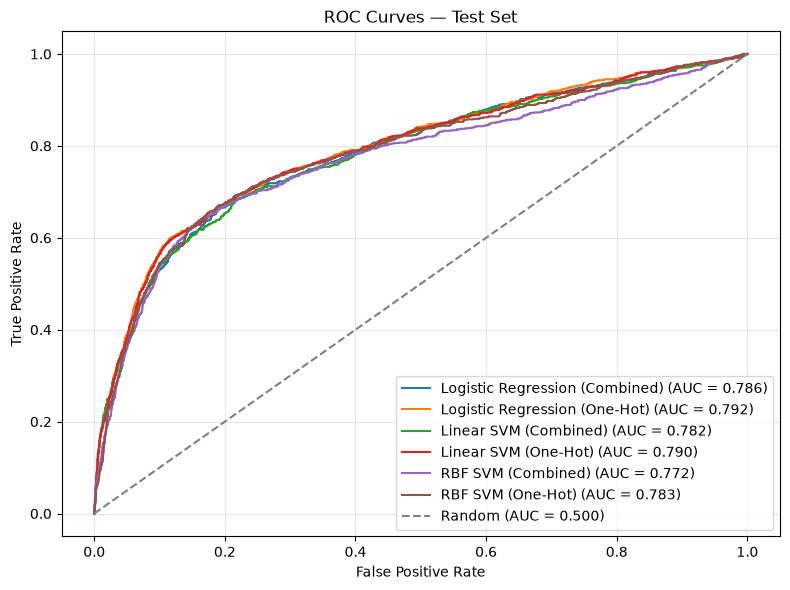

In [9]:
plt.figure(figsize=(8, 6))

for name, predictions in test_predictions.items():
    fpr, tpr, _ = roc_curve(
        y_test,
        predictions['y_score']
    )

    auc = test_results[name]['ROC-AUC']

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

# Случайное ранжирование
plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Random (AUC = 0.500)'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Test Set')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.2. Precision-Recall-кривые

Построим Precision-Recall-кривые для сравнения качества обнаружения положительного класса при различных порогах.

Дополнительно отобразим базовый уровень Precision, равный доле положительного класса в тестовой выборке.

Основной метрикой сравнения остаётся Average Precision.


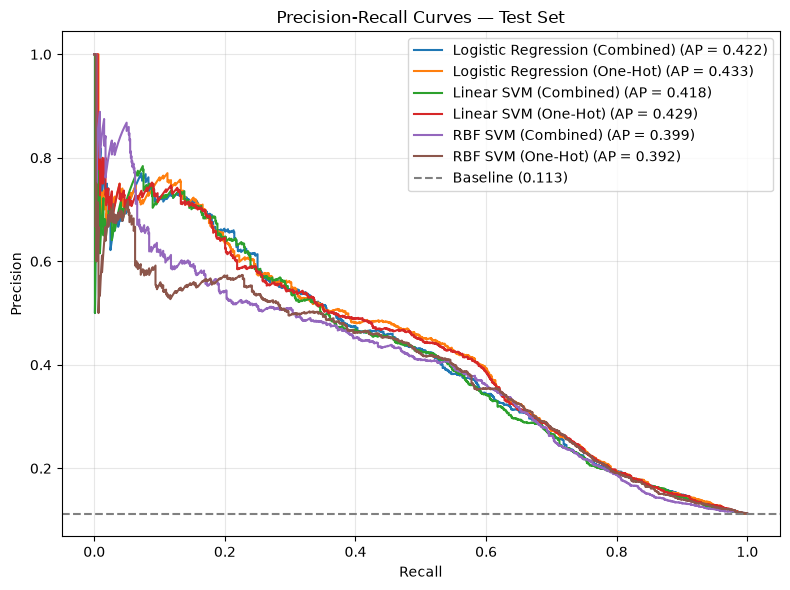

In [10]:
plt.figure(figsize=(8, 6))

for name, predictions in test_predictions.items():
    precision, recall, _ = precision_recall_curve(
        y_test,
        predictions['y_score']
    )

    ap = test_results[name]['AP']

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap:.3f})'
    )

# Базовый уровень Precision
baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle='--',
    color='gray',
    label=f'Baseline ({baseline:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves — Test Set')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.3. Сравнение моделей

Logistic Regression с One-Hot Encoding показала наибольшие ROC-AUC (0.7925) и Average Precision (0.4326), сохранив преимущество на тестовой выборке.

Линейные модели показали близкое качество ранжирования. RBF SVM уступила им по Average Precision, хотя по ROC-AUC различия оказались менее выраженными.

При этом ROC- и PR-кривые пересекаются: преимущество модели по интегральной метрике не означает лучшего качества при любом пороге.

Для дальнейшей оценки практической применимости моделей рассмотрим ошибки классификации и влияние порога принятия решения.


## 4. Анализ ошибок классификации

Проанализируем ошибки моделей при стандартных порогах классификации.

Построим матрицы ошибок, сравним количество ложноположительных (FP) и ложноотрицательных (FN) предсказаний и рассмотрим их значение для банковского маркетинга.



### 4.1. Матрицы ошибок

Построим матрицы ошибок для всех моделей на тестовой выборке.

Строки соответствуют фактическим классам, столбцы — предсказанным. Для оценки используем стандартные пороги классификаторов.


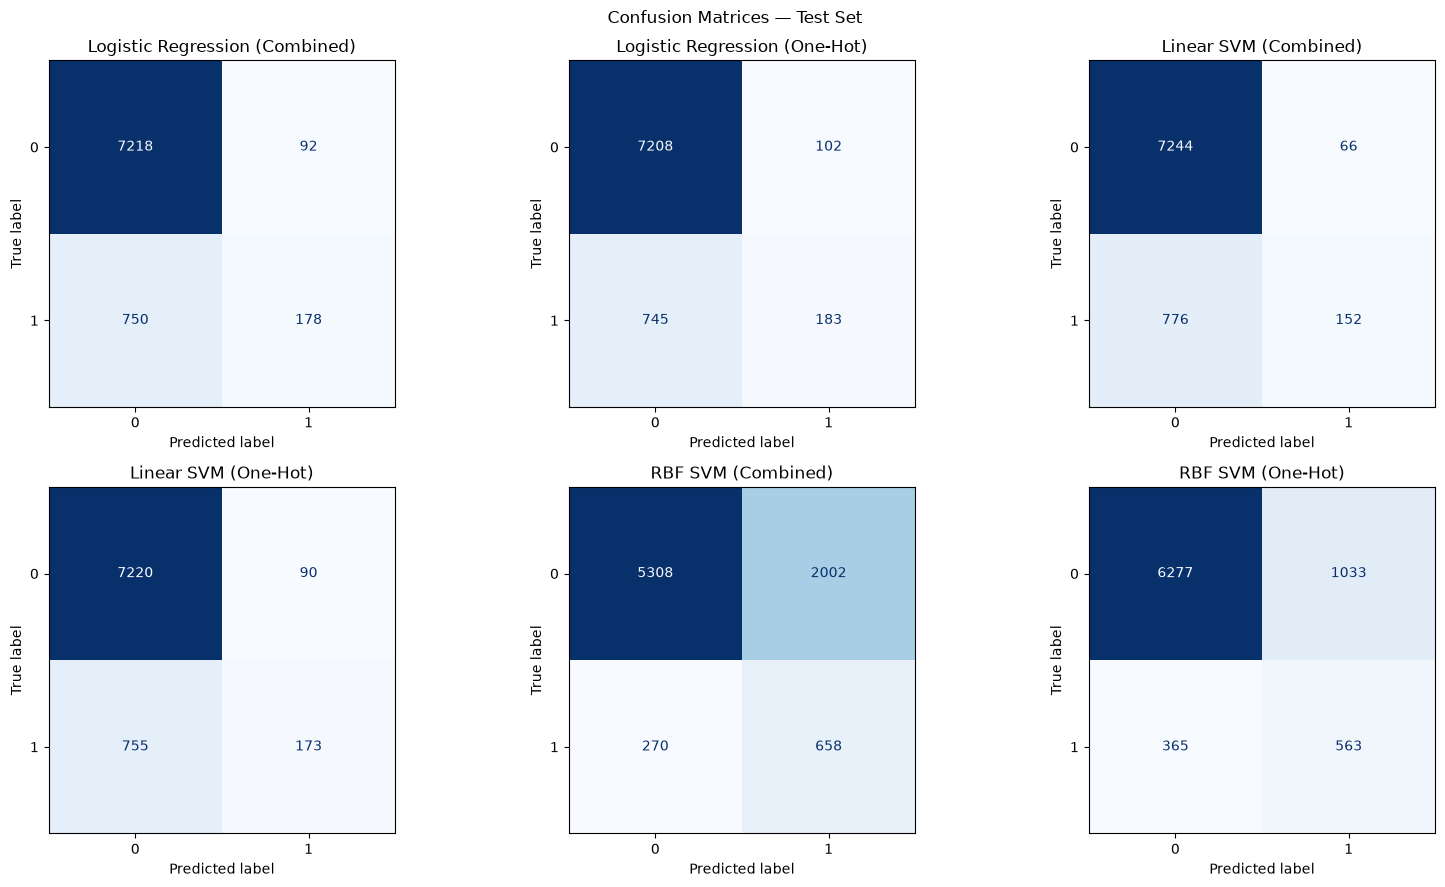

In [11]:
n_models = len(test_predictions)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 9)
)

axes = np.ravel(axes)

for ax, (name, predictions) in zip(
    axes, test_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions['y_pred'],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['0', '1']
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False,
        values_format='d'
    )

    ax.set_title(name)

# Убираем пустые графики, если моделей меньше,
# чем доступных мест в сетке
for ax in axes[n_models:]:
    ax.axis('off')

plt.suptitle('Confusion Matrices — Test Set')
plt.tight_layout()
plt.show()



### 4.2. False Positive и False Negative

Сравним количество ошибок каждого типа и рассчитаем False Positive Rate (FPR) и False Negative Rate (FNR).

Эти показатели позволят учесть различия в численности классов и оценить, насколько часто модели ошибаются отдельно на отрицательных и положительных наблюдениях.


In [12]:
error_results = {}

for name, predictions in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions['y_pred'],
        labels=[0, 1]
    ).ravel()

    error_results[name] = {
        'FP': fp,
        'FN': fn,
        'FPR': fp / (fp + tn),
        'FNR': fn / (fn + tp)
    }

error_comparison = pd.DataFrame.from_dict(
    error_results,
    orient='index'
)

error_comparison.round(4)

,FP,FN,FPR,FNR
Logistic Regression (Combined),92,750,0.0126,0.8082
Logistic Regression (One-Hot),102,745,0.0140,0.8028
Linear SVM (Combined),66,776,0.0090,0.8362
Linear SVM (One-Hot),90,755,0.0123,0.8136
RBF SVM (Combined),2002,270,0.2739,0.2909
RBF SVM (One-Hot),1033,365,0.1413,0.3933



### 4.3. Интерпретация ошибок

Линейные модели редко ошибочно предсказывают положительный класс, но пропускают значительную часть клиентов с положительным откликом. Например, Logistic Regression с One-Hot Encoding допустила 102 ложноположительных и 745 ложноотрицательных предсказаний (Recall = 0.1972).

RBF SVM (Combined) обнаружила значительно больше положительных клиентов (Recall = 0.7091), сократив количество FN до 270. Однако число FP увеличилось до 2002, а Precision снизилась до 0.2474.

Таким образом, модели демонстрируют разный баланс между FP и FN. Поскольку используются стандартные пороги классификации, а RBF SVM дополнительно обучалась со взвешиванием классов, различия не позволяют однозначно определить наиболее подходящий алгоритм.

Далее исследуем влияние порога классификации на Precision и Recall.

### 4.4. Проверка влияния совпадающих наблюдений

Проверим, отличается ли качество Logistic Regression на тестовых наблюдениях, признаки которых уже встречались в Train.

In [13]:
# Совпадения признаков между Train и Test
train_hash = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hash = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap_mask = test_hash.isin(set(train_hash)).to_numpy()

# Оценки лучшей модели
model_name = 'Logistic Regression (One-Hot)'
y_score = np.asarray(test_predictions[model_name]['y_score'])

# Сравнение групп
results = []

groups = {
    'Весь Test': np.ones(len(y_test), dtype=bool),
    'Совпадающие X': overlap_mask,
    'Без совпадений X': ~overlap_mask
}

for name, mask in groups.items():
    y_group = y_test.to_numpy()[mask]
    score_group = y_score[mask]

    results.append({
        'Группа': name,
        'Наблюдений': len(y_group),
        'Positive rate': y_group.mean(),
        'AP': average_precision_score(y_group, score_group),
        'ROC-AUC': roc_auc_score(y_group, score_group)
    })

overlap_comparison = pd.DataFrame(results).set_index('Группа')

overlap_comparison.round(4)

,Наблюдений,Positive rate,AP,ROC-AUC
Группа,,,,
Весь Test,8238,0.1126,0.4326,0.7925
Совпадающие X,591,0.0998,0.2897,0.7469
Без совпадений X,7647,0.1136,0.4422,0.7954


### Выводы

У 591 наблюдения из Test (7.17%) нашлись совпадения по признакам в Train.

На совпадающих наблюдениях модель показала AP = 0.2897 и ROC-AUC = 0.7469. На остальных качество оказалось немного выше, чем на полном Test: AP = 0.4422 против 0.4326, ROC-AUC = 0.7954 против 0.7925.

По этим результатам совпадения не выглядят причиной завышения метрик. Однако группы различаются по составу и доле положительного класса, поэтому однозначно оценить влияние совпадений нельзя.

Исходное разделение данных и обученная модель остались без изменений.



## 5. Выбор порога классификации

При стандартном пороге 0.5 Logistic Regression с One-Hot Encoding обнаруживает только около 20% клиентов с положительным откликом, несмотря на сравнительно высокую Precision.

Исследуем, как изменение порога влияет на Precision и Recall. Для выбора порога используем внефолдовые предсказания на обучающей выборке, после чего оценим полученный результат на Test.



### 5.1. Влияние порога на Precision и Recall

Получим внефолдовые вероятности положительного класса с помощью `cross_val_predict`.

Для каждого наблюдения предсказание будет сделано моделью, не обучавшейся на соответствующем валидационном фолде.

На основе полученных вероятностей исследуем зависимость Precision и Recall от порога классификации.


In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
best_model_name = 'Logistic Regression (One-Hot)'
best_model = models[best_model_name]

oof_proba = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

In [16]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_proba
)

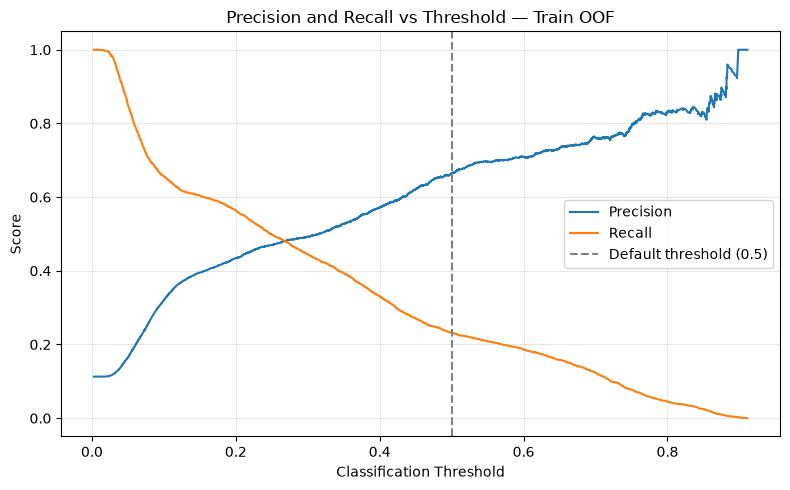

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    precision[:-1],
    label='Precision'
)

plt.plot(
    thresholds,
    recall[:-1],
    label='Recall'
)

plt.axvline(
    0.5,
    color='gray',
    linestyle='--',
    label='Default threshold (0.5)'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold — Train OOF')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.2. Подбор порога на обучающих данных

Поскольку стоимость ошибок FP и FN неизвестна, в качестве экспериментального критерия выбора порога используем максимизацию F1-score.

Рассчитаем F1 для порогов на основе OOF-предсказаний и выберем значение, при котором метрика достигает максимума.

Полученный порог зафиксируем до оценки на тестовой выборке.


In [18]:
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold_idx = np.argmax(f1_values)

best_threshold = thresholds[best_threshold_idx]

print('Оптимальный порог:', round(best_threshold, 4))
print('OOF Precision:', round(precision[best_threshold_idx], 4))
print('OOF Recall:', round(recall[best_threshold_idx], 4))
print('OOF F1:', round(f1_values[best_threshold_idx], 4))

Оптимальный порог: 0.2129
OOF Precision: 0.4465
OOF Recall: 0.5493
OOF F1: 0.4926


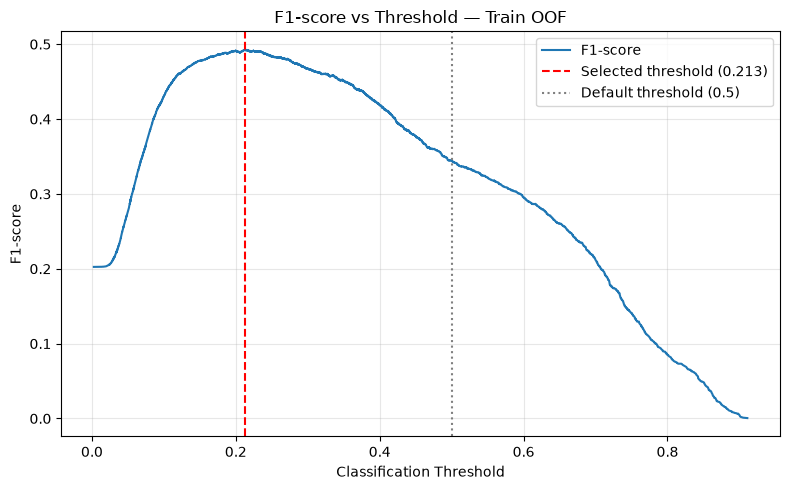

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    f1_values,
    label='F1-score'
)

plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    label=f'Selected threshold ({best_threshold:.3f})'
)

plt.axvline(
    0.5,
    color='gray',
    linestyle=':',
    label='Default threshold (0.5)'
)

plt.xlabel('Classification Threshold')
plt.ylabel('F1-score')
plt.title('F1-score vs Threshold — Train OOF')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.3. Оценка выбранного порога на Test

Применим порог, выбранный по OOF-предсказаниям на Train, к вероятностям тестовой выборки.

Сравним Precision, Recall и F1-score со значениями при стандартном пороге 0.5, а также количество ошибок FP и FN.

Average Precision и ROC-AUC не изменятся, поскольку выбор порога не влияет на исходные вероятности и ранжирование наблюдений.


In [20]:
y_score_test = test_predictions[best_model_name]['y_score']

y_pred_default = test_predictions[best_model_name]['y_pred']

y_pred_tuned = (y_score_test >= best_threshold).astype(int)

In [21]:
threshold_results = {}

for name, y_pred in {
    'Default (0.5)': y_pred_default,
    'Tuned': y_pred_tuned
}.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    threshold_results[name] = {
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'FP': fp,
        'FN': fn
    }

threshold_comparison = pd.DataFrame.from_dict(
    threshold_results,
    orient='index'
)

threshold_comparison.round(4)

,Precision,Recall,F1,FP,FN
Default (0.5),0.6421,0.1972,0.3017,102,745
Tuned,0.4370,0.5377,0.4821,643,429



### Выводы

- По OOF-предсказаниям на обучающей выборке выбран порог 0.2129, максимизирующий F1-score.
- На тестовой выборке Recall увеличился с 0.1972 до 0.5377, а F1 — с 0.3017 до 0.4821. При этом Precision снизилась с 0.6421 до 0.4370.
- Количество пропущенных положительных клиентов (FN) сократилось с 745 до 429, однако число ложноположительных предсказаний (FP) увеличилось со 102 до 643.
- Изменение порога позволило повысить Recall без повторного обучения модели. Average Precision и ROC-AUC остались неизменными.
- Выбранный порог оптимизирован по F1, но не обязательно обеспечивает максимальную экономическую эффективность маркетинговой кампании.



## 6. Практическая ценность моделей

При ограниченном бюджете банк может связываться не со всеми клиентами, а только с теми, кому модель присвоила наиболее высокие оценки.

Проверим эффективность такого отбора с помощью Precision@K, Recall@K и Lift@K. Основное внимание уделим Logistic Regression с One-Hot Encoding, которая показала лучший AP на кросс-валидации.



### 6.1. Precision@K и Recall@K

Отсортируем клиентов по непрерывным оценкам моделей и рассчитаем Precision@K и Recall@K для различных размеров целевой аудитории.

Рассмотрим топ-5%, 10%, 20% и 30% клиентов. Эти доли используются как сценарии ограниченного числа контактов, а не выбираются для максимизации метрик на тестовой выборке.


In [22]:
def calculate_top_k_metrics(y_true, y_score, share):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    k = int(np.ceil(len(y_true) * share))

    # Индексы клиентов с наибольшими оценками
    top_idx = np.argsort(-y_score, kind='stable')[:k]

    # Количество положительных клиентов в топ-K
    positives_at_k = int(y_true[top_idx].sum())

    precision_at_k = positives_at_k / k
    recall_at_k = positives_at_k / y_true.sum()

    return {
        'Share': share,
        'K': k,
        'Positives@K': positives_at_k,
        'Precision@K': precision_at_k,
        'Recall@K': recall_at_k
    }

In [23]:
shares = [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]

top_k_results = []

for name, predictions in test_predictions.items():
    for share in shares:
        metrics = calculate_top_k_metrics(
            y_test,
            predictions['y_score'],
            share
        )

        top_k_results.append({
            'Model': name,
            **metrics
        })

top_k_results = pd.DataFrame(top_k_results)

In [24]:
best_top_k = top_k_results[
    (top_k_results['Model'] == best_model_name)
    & (top_k_results['Share'] <= 0.30)
].drop(columns='Model')

best_top_k.round(4)

,Share,K,Positives@K,Precision@K,Recall@K
6,0.05,412,236,0.5728,0.2543
7,0.10,824,399,0.4842,0.4300
8,0.20,1648,576,0.3495,0.6207
9,0.30,2472,659,0.2666,0.7101



### 6.2. Lift@K

Рассчитаем Lift@K как отношение Precision@K к общей доле положительного класса.

Lift = 1 соответствует базовому уровню случайного отбора, а значения выше 1 показывают, во сколько раз положительный отклик чаще встречается среди клиентов с наиболее высокими оценками.
Сравним Lift@K шести моделей при разных размерах целевой аудитории.

In [25]:
baseline_rate = y_test.mean()

top_k_results['Lift@K'] = (
    top_k_results['Precision@K'] / baseline_rate
)

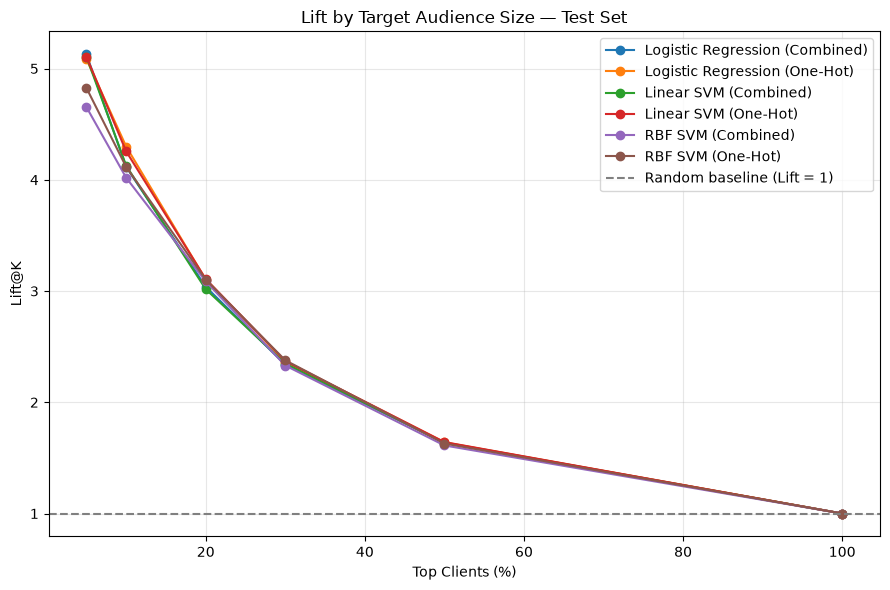

In [26]:
plt.figure(figsize=(9, 6))

for name, group in top_k_results.groupby('Model', sort=False):
    plt.plot(
        group['Share'] * 100,
        group['Lift@K'],
        marker='o',
        label=name
    )

plt.axhline(
    1,
    color='gray',
    linestyle='--',
    label='Random baseline (Lift = 1)'
)

plt.xlabel('Top Clients (%)')
plt.ylabel('Lift@K')
plt.title('Lift by Target Audience Size — Test Set')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
top_10_comparison = (
    top_k_results[top_k_results['Share'] == 0.10]
    .drop(columns='Share')
    .set_index('Model')
    .sort_values('Lift@K', ascending=False)
)

top_10_comparison.round(4)

,K,Positives@K,Precision@K,Recall@K,Lift@K
Model,,,,,
Logistic Regression (One-Hot),824,399,0.4842,0.4300,4.2985
Linear SVM (One-Hot),824,395,0.4794,0.4256,4.2554
Linear SVM (Combined),824,383,0.4648,0.4127,4.1262
Logistic Regression (Combined),824,382,0.4636,0.4116,4.1154
RBF SVM (One-Hot),824,382,0.4636,0.4116,4.1154
RBF SVM (Combined),824,373,0.4527,0.4019,4.0184



### 6.3. Интерпретация для банковского маркетинга

Logistic Regression с One-Hot Encoding показала лучший результат при отборе топ-10% клиентов. Среди 824 выбранных наблюдений положительный отклик имели 399 клиентов. Precision@10% составила 0.4842, Recall@10% — 0.4300, а Lift@10% — 4.30.

При расширении аудитории до 20% Recall увеличивается до 0.6207, но Precision снижается до 0.3495. Таким образом, увеличение числа контактов позволяет охватить больше положительных клиентов, однако средняя результативность выбранной группы уменьшается.

Результаты показывают, что ранжирование может быть полезно для распределения ограниченного числа контактов. При этом метрики рассчитаны на исторических данных и не отражают дополнительный эффект звонков. Для оценки экономической выгоды необходимы данные о стоимости контактов, доходе от привлечения клиентов и результатах контрольной группы.



## 7. Итоговые выводы

### 7.1. Сравнение моделей

Лучший результат на Test показала Logistic Regression с One-Hot Encoding: AP = 0.4326 и ROC-AUC = 0.7925. Linear SVM при таком же кодировании получила близкий AP = 0.4293.

One-Hot Encoding улучшил AP логистической регрессии и Linear SVM как на кросс-валидации, так и на Test. У RBF SVM результат оказался неоднозначным: AP выросла на кросс-валидации, но снизилась на Test с 0.3986 до 0.3920.

При одинаковой предобработке Logistic Regression немного опережает Linear SVM, а RBF SVM уступает обеим моделям по основной метрике. Однако разница между двумя линейными моделями небольшая.

### 7.2. Ограничения исследования

Случайное разделение данных не позволяет оценить устойчивость моделей на будущих банковских кампаниях. Для этого необходима хронологическая валидация, учитывающая возможные изменения экономических условий и поведения клиентов.

Кроме того, данные отражают исторические результаты маркетинговых контактов. Высокий Lift показывает концентрацию положительных откликов среди выбранных клиентов, но не доказывает дополнительный эффект звонков. Для такой оценки необходим эксперимент с контрольной группой.

В датасете также отсутствуют сведения о стоимости контактов и доходе от привлечённых клиентов. Поэтому выбранный по F1 порог нельзя считать экономически оптимальным.

### 7.3. Итоговая рекомендация

Для дальнейшего использования наиболее перспективна Logistic Regression с One-Hot Encoding.

При ограниченном числе контактов предпочтительнее ранжировать клиентов и выбирать группу заданного размера. В топ-10% клиентов по оценке модели попали 399 из 928 положительных наблюдений. Precision@10% составила 48.4%, Lift@10% — 4.30.

Если требуется бинарное решение, можно использовать порог 0.2129 как экспериментальную отправную точку, но окончательный выбор должен учитывать стоимость ошибок и бюджет кампании.

Перед практическим применением модели необходимо проверить её на более поздних данных и оценить экономическую эффективность.
